In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [9]:
df = pd.read_csv("sentimentdataset.csv")
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [10]:
print("\n Dataset Information")
df.info()

print("\n Missing Value")
print(df.isnull().sum())

print("\n Numerical Summary")
print(df.describe())

print("\n Sentiment Classes")
print(df["Sentiment"].value_counts())


 Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    str    
 3   Sentiment     732 non-null    str    
 4   Timestamp     732 non-null    str    
 5   User          732 non-null    str    
 6   Platform      732 non-null    str    
 7   Hashtags      732 non-null    str    
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    str    
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), str(7)
memory usage: 85.9 KB

 Missing Value
Unnamed: 0.1    0
Unnamed: 0      0
Text            0
Sentiment       0
Timest

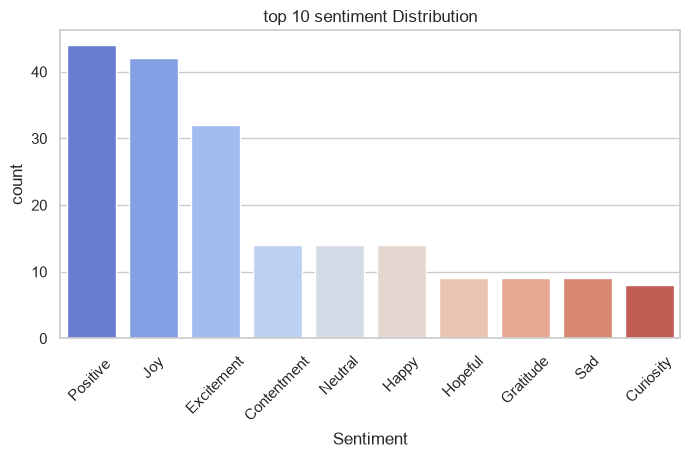

In [12]:
top_sentiments = df["Sentiment"].value_counts().nlargest(10).index
df_top = df[df["Sentiment"].isin(top_sentiments)]

plt.figure(figsize=(8,4))
sns.countplot(data=df_top,x="Sentiment",palette="coolwarm",order=top_sentiments)
plt.title("top 10 sentiment Distribution")
plt.xticks(rotation=45)
plt.show()

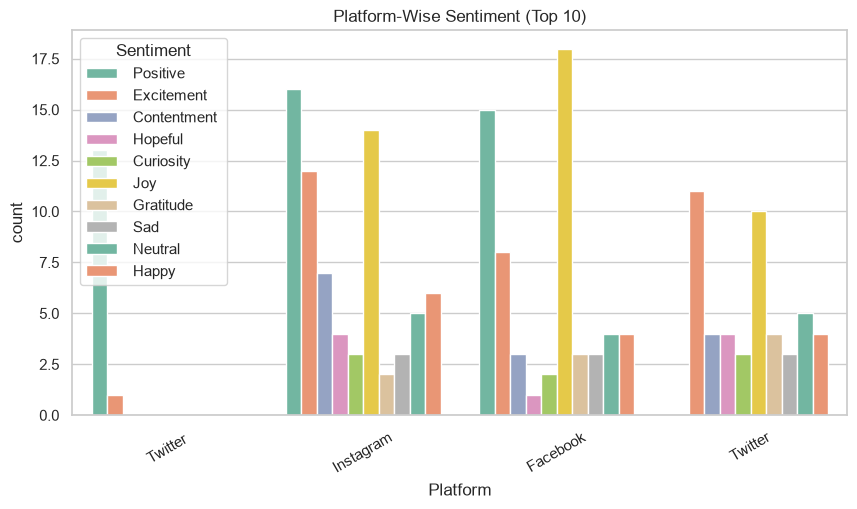

In [13]:
plt.figure(figsize=(10,5))
sns.countplot(data=df_top,x="Platform",hue="Sentiment",palette="Set2")
plt.title("Platform-Wise Sentiment (Top 10)")
plt.xticks(rotation=30)
plt.show()

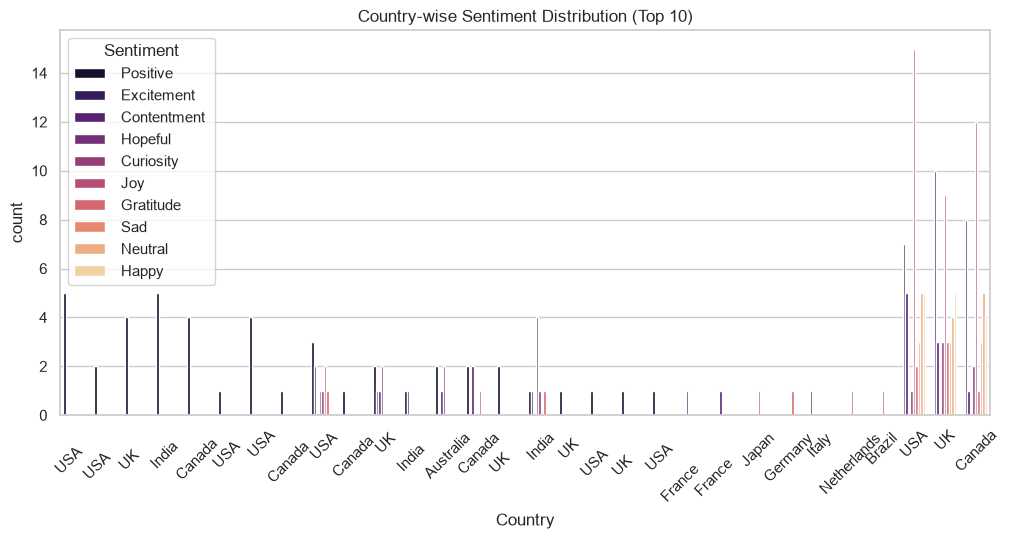

In [14]:
plt.figure(figsize=(12,5))
sns.countplot(data=df_top,x="Country",hue="Sentiment",palette="magma")
plt.title("Country-wise Sentiment Distribution (Top 10)")
plt.xticks(rotation=45)
plt.show()

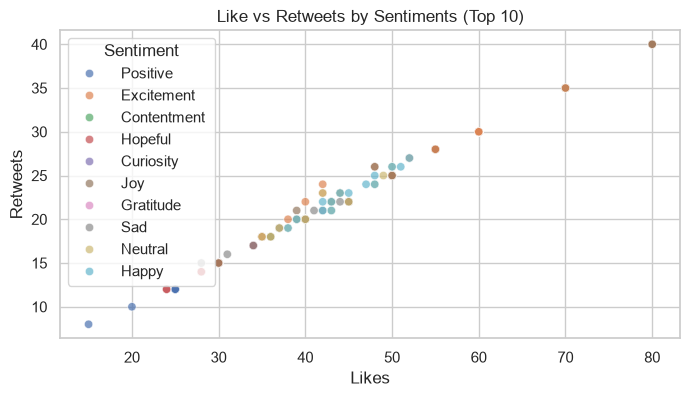

In [16]:
plt.figure(figsize=(8,4))
sns.scatterplot(data=df_top,x="Likes",y="Retweets",hue="Sentiment",alpha=0.7)
plt.title("Like vs Retweets by Sentiments (Top 10)")
plt.show()

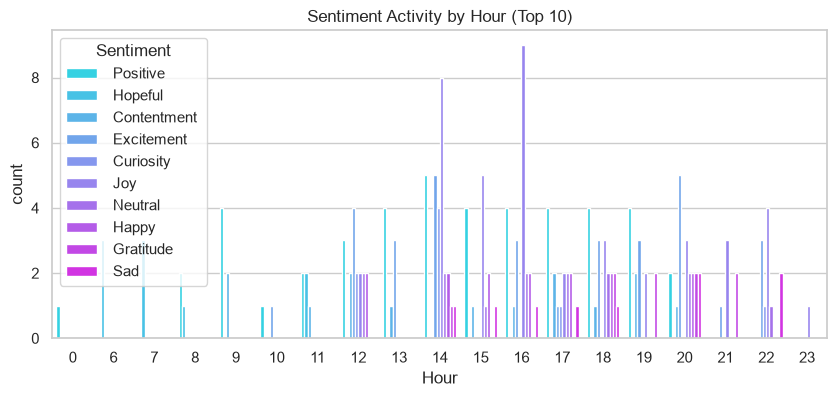

In [17]:
plt.figure(figsize=(10,4))
sns.countplot(data=df_top,x="Hour",hue="Sentiment",palette="cool")
plt.title("Sentiment Activity by Hour (Top 10)")
plt.show()

In [19]:
%pip install nltk

  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------------ --------------------- 0.8/1.7 MB 1.6 MB/s eta 0:00:01
   ------------------ --------------------- 0.8/1.7 MB 1.6 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 1.4 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 1.4 MB/s eta 0:00:01
   ------------------------------ --------- 1.3/1.7 MB 1.0 MB/s eta 0:00:01
   ------------------------------------ --- 1.6/1.7 MB 1.0 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 959.6 kB/s  0:00:01
Using cached click-8.5.1-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   -------- ------------------------------- 1/5 [reg


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to C:\Users\Yash J
[nltk_data]     Patil\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [21]:
def clean_text(text):
    text = str(text).lower()                         # Convert to lowercase
    text = re.sub(r'<.*?>', '', text)                # Remove HTML tags
    text = re.sub(r'https?://\S+|www\.\S+', '', text) # Remove URLs
    text = re.sub(r'\d+', '', text)                  # Remove numbers
    text = re.sub(r'[^a-z\s]', '', text)             # Remove punctuation and special characters
    text = re.sub(r'\s+', ' ', text).strip()          # Remove extra spaces

    return text

In [22]:
df["Clean_Text"] = df["Text"].apply(clean_text)
df[["Text","Clean_Text"]].head(10)

,Text,Clean_Text
0,Enjoying a beautiful day at the park! ...,enjoying a beautiful day at the park
1,Traffic was terrible this morning. ...,traffic was terrible this morning
2,Just finished an amazing workout! 💪 ...,just finished an amazing workout
3,Excited about the upcoming weekend getaway! ...,excited about the upcoming weekend getaway
4,Trying out a new recipe for dinner tonight. ...,trying out a new recipe for dinner tonight
5,Feeling grateful for the little things in lif...,feeling grateful for the little things in life
6,Rainy days call for cozy blankets and hot coc...,rainy days call for cozy blankets and hot cocoa
7,The new movie release is a must-watch! ...,the new movie release is a mustwatch
8,Political discussions heating up on the timel...,political discussions heating up on the timeline
9,Missing summer vibes and beach days. ...,missing summer vibes and beach days


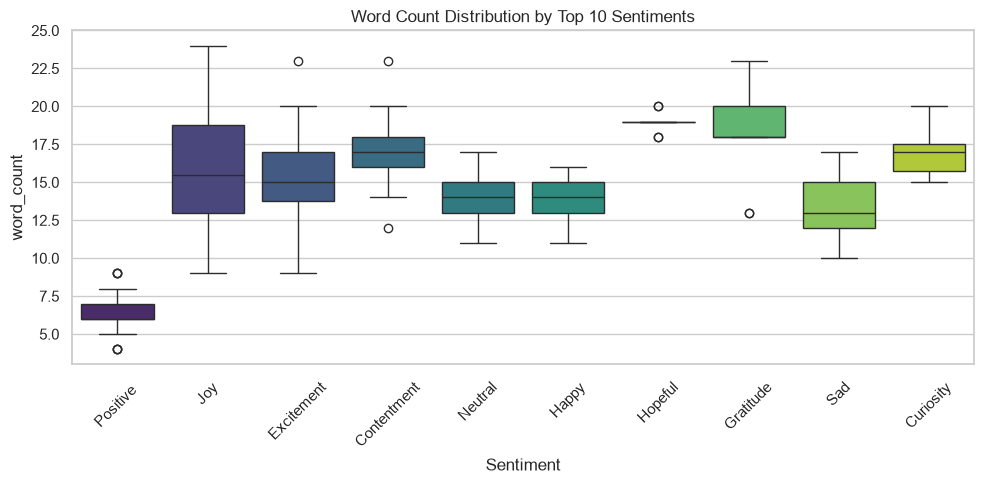


Top words for  Positive  :


,Word,Frequency
0,a,22
1,the,13
2,new,10
3,with,7
4,for,5



Top words for  Joy :


,Word,Frequency
0,the,48
1,a,46
2,of,21
3,in,14
4,to,10



Top words for  Excitement :


,Word,Frequency
0,the,39
1,a,31
2,of,16
3,to,13
4,for,11


... (10 outputs left out)


Top words for  Sad :


,Word,Frequency
0,a,11
1,feeling,5
2,with,4
3,on,3
4,the,3



Top words for  Curiosity :


,Word,Frequency
0,the,13
1,of,8
2,a,8
3,new,4
4,to,3


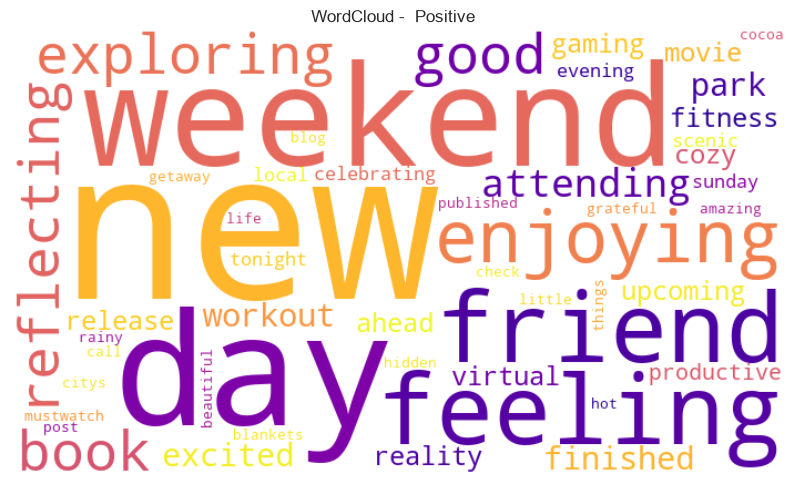

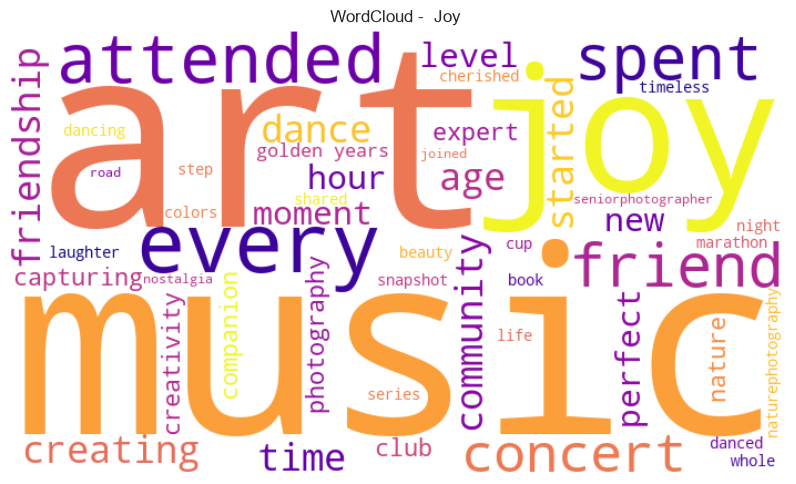

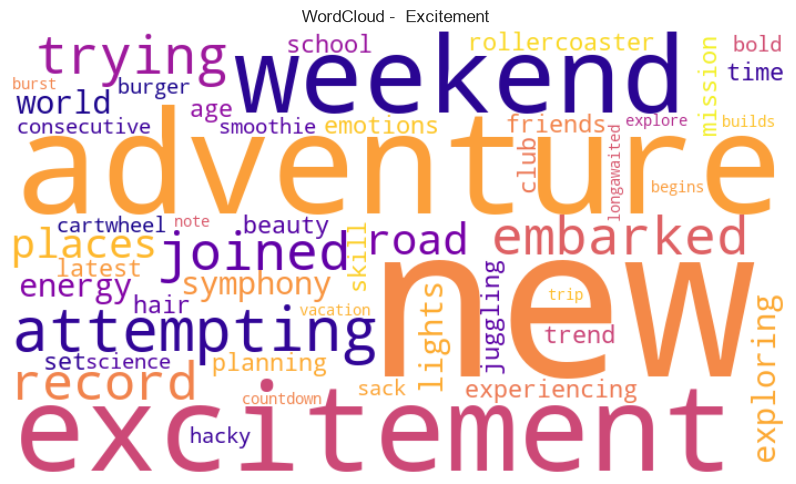

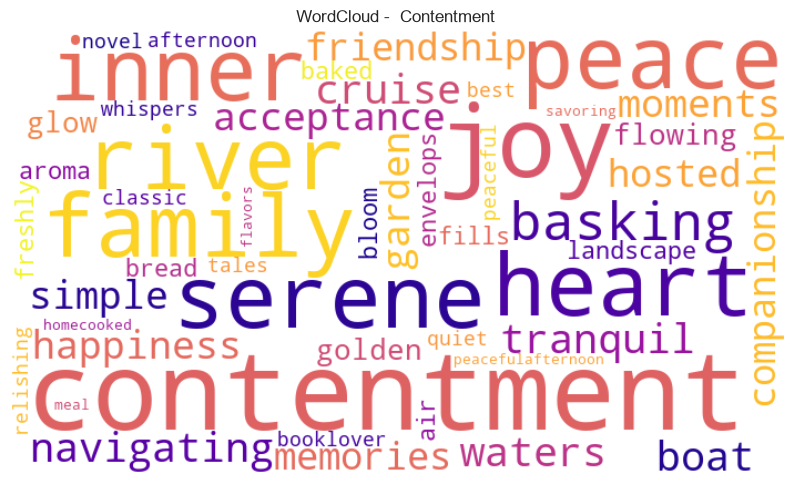

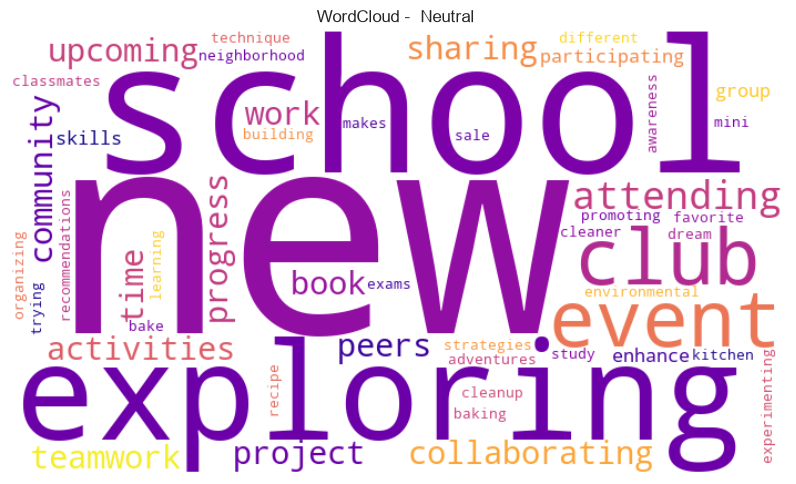

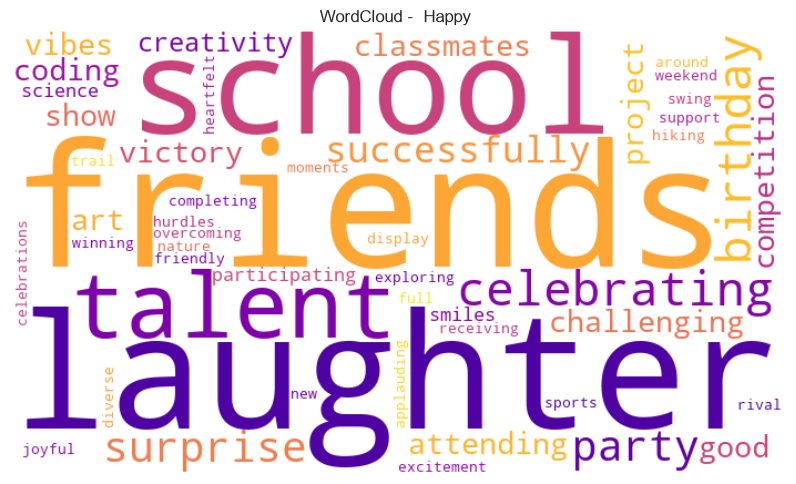

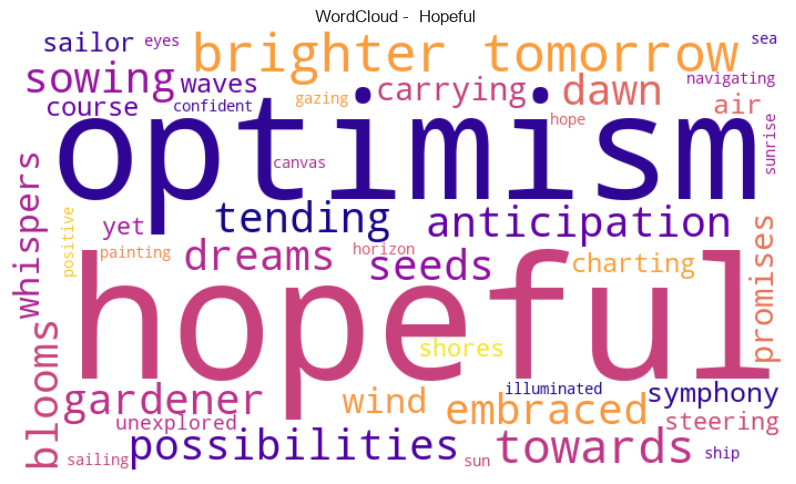

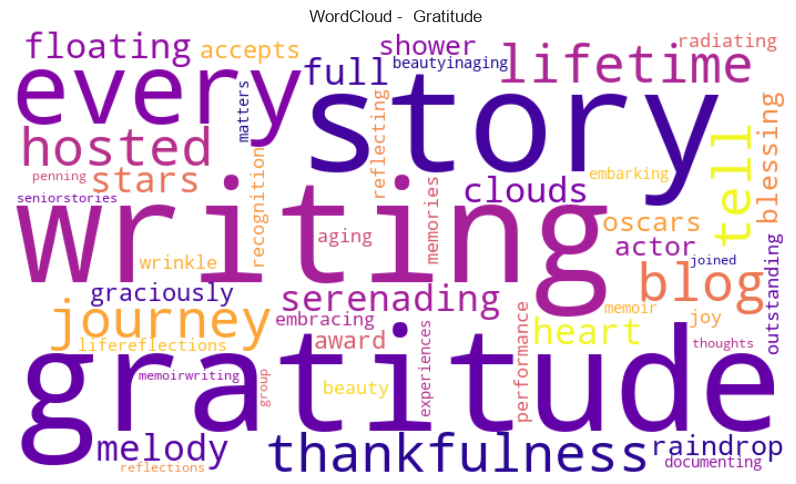

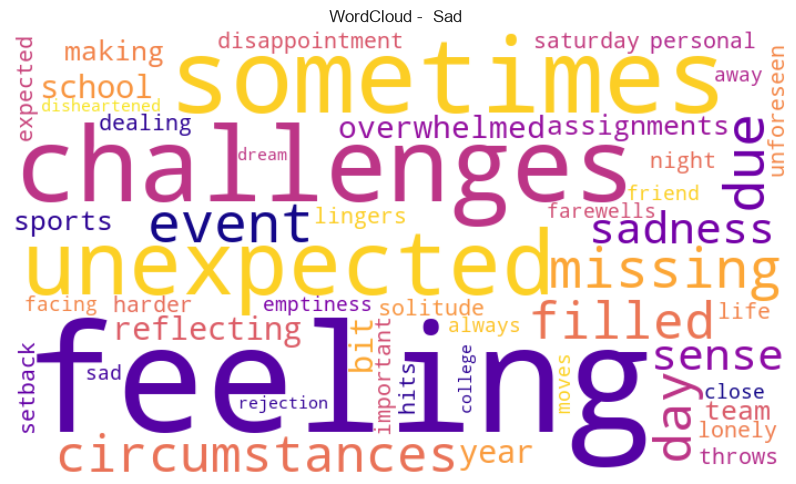

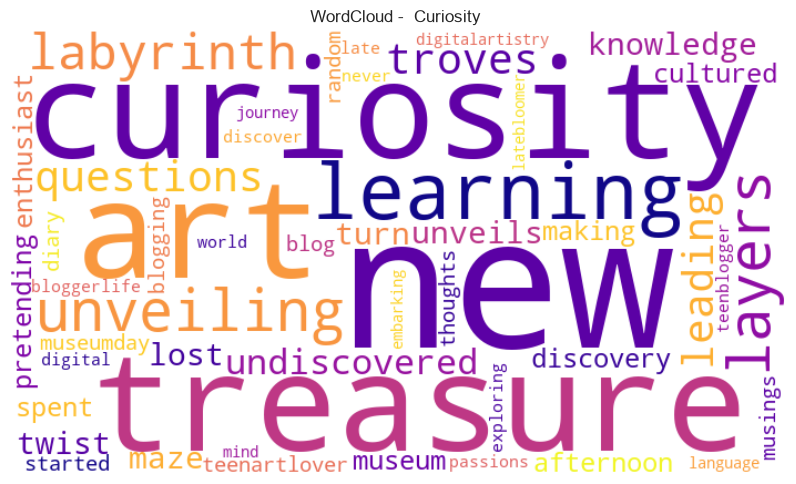

In [23]:
# Select top 10 most frequent sentiments
top_sentiments = df['Sentiment'].value_counts().nlargest(10).index
df_top = df[df['Sentiment'].isin(top_sentiments)].copy()


#Average Word Count per Sentiment (Top 10)
df_top['word_count'] = df_top['Clean_Text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_top,
    x='Sentiment',
    y='word_count',
    palette='viridis',
    order=top_sentiments
)

plt.title('Word Count Distribution by Top 10 Sentiments')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Most Common Words per Sentiment (Top 10 sentiments, top 5 words each)

def most_common_words(sentiment, n=5):
    words = " ".join(
        df_top[df_top['Sentiment'] == sentiment]['Clean_Text']
    ).split()

    common = Counter(words).most_common(n)

    return pd.DataFrame(common, columns=['Word', 'Frequency'])


for s in top_sentiments:
    print(f"\nTop words for {s}:")
    display(most_common_words(s, n=5))


# WordClouds for Top 10 Sentiments

for sentiment in top_sentiments:
    text = " ".join(
        df_top[df_top['Sentiment'] == sentiment]['Clean_Text']
    )

    if text.strip():
        wc = WordCloud(
            width=700,
            height=400,
            background_color='white',
            colormap='plasma',
            max_words=50
        ).generate(text)

        plt.figure(figsize=(10, 5))
        plt.imshow(wc, interpolation='bilinear')
        plt.axis('off')
        plt.title(f"WordCloud - {sentiment}")
        plt.tight_layout()
        plt.show()

In [25]:
counts = df["Sentiment"].value_counts()
rare_classes= counts[counts < 2].index
df["Sentiment"] = df["Sentiment"].replace(rare_classes,"Other")

#TF-IDF
tfidf = TfidfVectorizer(
    max_features=1500,
    ngram_range = (1,3),
    min_df=2,
    max_df=0.95
)

X=tfidf.fit_transform(df["Clean_Text"])
y=df["Sentiment"]

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42, stratify=y)

print("Train shape:",X_train.shape,"Test shape:",X_test.shape)

Train shape: (549, 1500) Test shape: (183, 1500)


In [26]:
models={
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM":LinearSVC(),
    "Random Forest":RandomForestClassifier(n_estimators=200, random_state=42)
}

result={}

for name, model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    acc=accuracy_score(y_test ,y_pred)
    result[name]= acc
    print(f"{name} Acurracy:{acc:.4f}")


Logistic Regression Acurracy:0.2240
Naive Bayes Acurracy:0.2022
Linear SVM Acurracy:0.4153
Random Forest Acurracy:0.4262


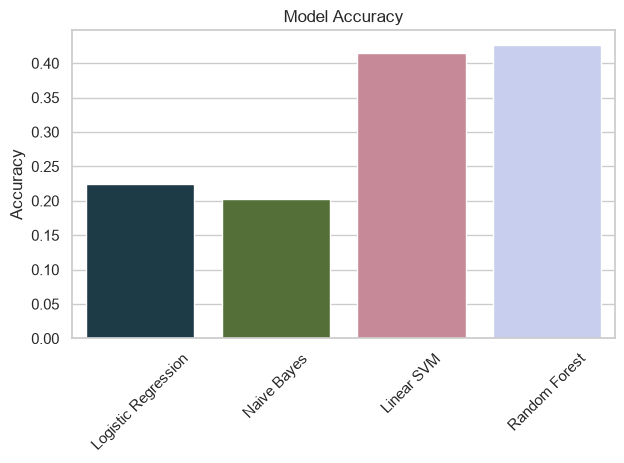


 Best performing: Random Forest(42.62%accuracy)


In [30]:
plt.figure(figsize=(7,4))
sns.barplot(x=list(result.keys()),y=list(result.values()),palette="cubehelix")
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

best_model_name= max(result, key=result.get)
print(f"\n Best performing: {best_model_name}({result[best_model_name]:.2%}accuracy)")

In [31]:
best_model=models[best_model_name]
y_pred_best = best_model.predict(X_test)

print("\n Classification Report")
print(classification_report(y_test, y_pred_best))


 Classification Report
                   precision    recall  f1-score   support

    Acceptance          0.00      0.00      0.00         1
 Acceptance             0.50      1.00      0.67         1
  Accomplishment        0.00      0.00      0.00         1
    Adoration           0.00      0.00      0.00         1
       Adventure        0.00      0.00      0.00         1
    Affection           0.00      0.00      0.00         1
 Ambivalence            1.00      1.00      1.00         1
    Amusement           0.00      0.00      0.00         1
    Apprehensive        0.00      0.00      0.00         1
   Arousal              1.00      1.00      1.00         1
             Awe        0.00      0.00      0.00         1
    Awe                 0.00      0.00      0.00         1
             Bad        1.00      1.00      1.00         1
        Betrayal        0.00      0.00      0.00         1
    Bitter              0.00      0.00      0.00         1
      Bitterness        1.00   

In [32]:
joblib.dump(best_model,"best_sentiment_model.pkl")
joblib.dump(tfidf,"tfidf_vectorizer.pkl")
print("\n Model and TF-IDF Vectorizer saved Sucessfully")


 Model and TF-IDF Vectorizer saved Sucessfully


In [34]:
def predict_sentiment(text):
    clean = clean_text(text)
    vec = tfidf.transform([clean])
    pred = best_model.predict(vec)[0]
    return pred

samples = [
    "I love this new Feature!",
    "The Service was awful and slow.",
    "It's okay,not too bad but not htat great either."
]

for s in samples:
    print(f"Text: {s} --> Sentiment: {predict_sentiment(s)}")

Text: I love this new Feature! --> Sentiment:  Positive  
Text: The Service was awful and slow. --> Sentiment: Other
Text: It's okay,not too bad but not htat great either. --> Sentiment:  Bad 


In [35]:
df.to_csv("cleaned_sentiment_dataset.csv", index=False)
print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully
